In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("IMDB Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
print("Dataset Information:")
df.info()

print("\nSentiment Distribution:")
print(df['sentiment'].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Rows: 418


In [4]:
before = df.shape[0]

df = df.drop_duplicates()

after = df.shape[0]

print("Rows Before:", before)
print("Rows After:", after)
print("Duplicates Removed:", before - after)

Rows Before: 50000
Rows After: 49582
Duplicates Removed: 418


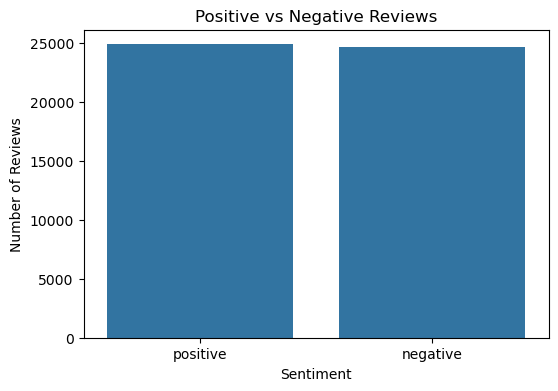

In [5]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='sentiment')

plt.title("Positive vs Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [6]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['cleaned_review'] = df['review'].apply(clean_text)

print("Text preprocessing completed!")
display(df[['review', 'cleaned_review']].head())

Text preprocessing completed!


,review,cleaned_review
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,basically there s a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love in the time of money is a...


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df['cleaned_review'])
y = df['sentiment']

print("TF-IDF conversion completed!")
print("Feature Shape:", X.shape)

TF-IDF conversion completed!
Feature Shape: (49582, 5000)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (39665, 5000)
Testing Data: (9917, 5000)


In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [10]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 89.089442371685 %

Classification Report:
              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      4940
    positive       0.88      0.90      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917



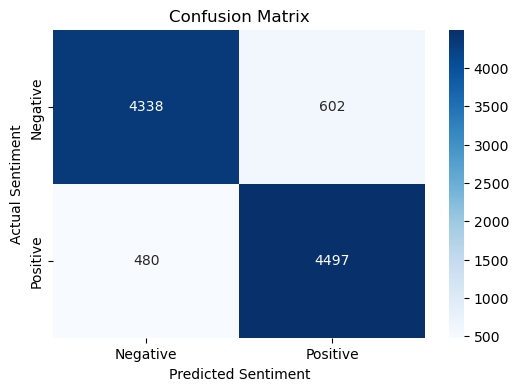

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [12]:
def predict_sentiment(review):
    cleaned = clean_text(review)
    vectorized = tfidf.transform([cleaned])
    prediction = model.predict(vectorized)
    return prediction[0]

print(predict_sentiment("This movie was amazing and wonderful!"))

print(predict_sentiment("This movie was boring and terrible."))

positive
negative


## Final Insights and Conclusion

### Key Findings
1. The dataset contains 50,000 movie reviews.
2. It contains 25,000 positive and 25,000 negative reviews.
3. A total of 418 duplicate reviews were removed.
4. Text preprocessing was performed to clean reviews.
5. TF-IDF was used to convert text into numerical features.
6. Logistic Regression was used for sentiment classification.
7. The model achieved **89.09% accuracy** on test data.

### Conclusion
The Sentiment Analysis project successfully classifies movie reviews into Positive and Negative categories using Natural Language Processing (NLP) and Machine Learning. The Logistic Regression model achieved 89.09% accuracy and can predict sentiment for new movie reviews.

In [13]:
df.to_csv("imdb_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
